# Ventes 11 · Synthèse finale

Données → trois modèles → benchmark → lissage (GCV / REML) → explicabilité et résidus avec les outils de TAM.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import matplotlib.pyplot as plt

from ventes_final import *          # module autonome, dans le même dossier que ce notebook
import tam as ta
from tam.common.plotting import plot_effect_with_data_decomposed, plot_component
from tam.common.utils import _ensure_dummies
from tam.model.diagnostics import run_diagnostics
from tam.evaluation import calculate_regression_metrics, deviance_explained, analyze_residuals, detect_temporal_degradation

# set_data_dir('chemin/vers/les/csv')   # si les données Kaggle ne sont pas trouvées automatiquement

plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

## 1. Données

54 magasins x 33 familles = 1,782 séries, du 01/01/2013 au 15/08/2017 ; ventes nulles : 31% des lignes


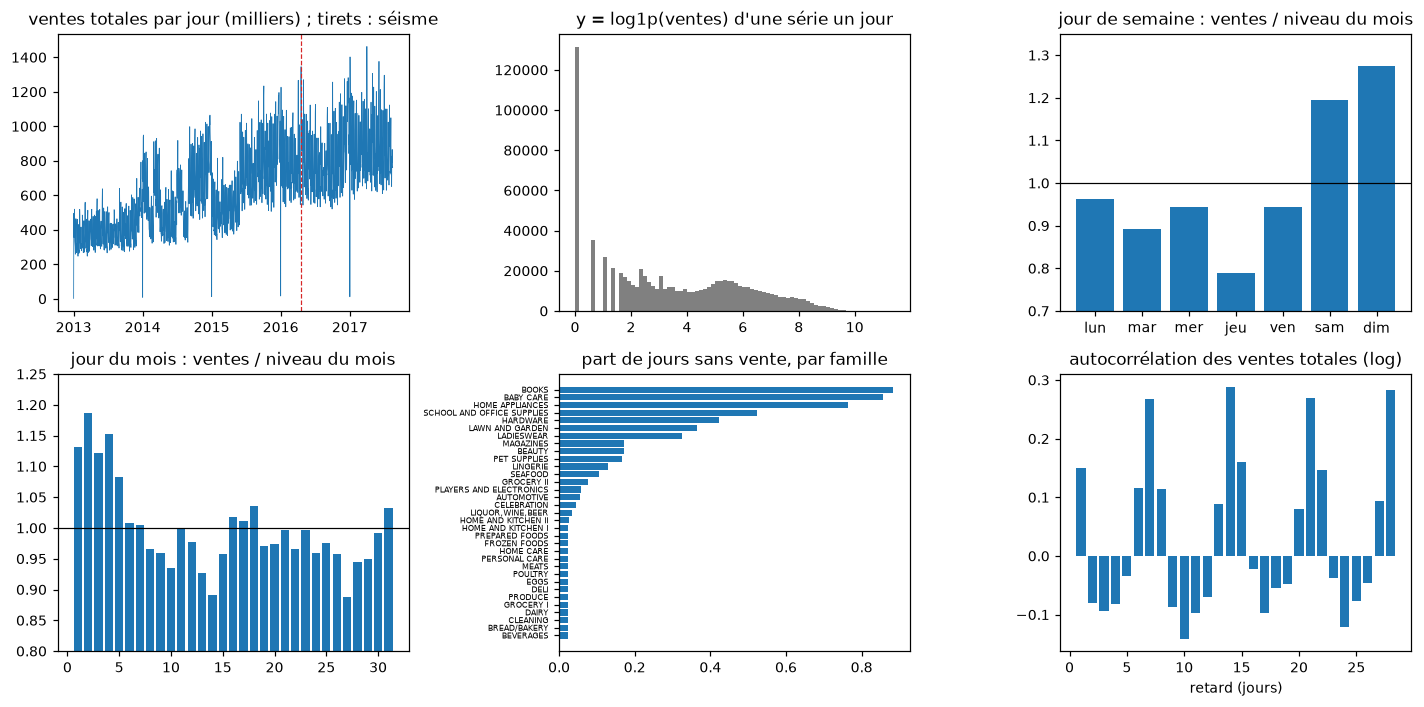

In [2]:
train_csv, test_csv, stores, oil, holidays, transactions = load_raw()
print(f"{train_csv['store_nbr'].nunique()} magasins x {train_csv['family'].nunique()} familles = "
      f"{train_csv.groupby(['store_nbr', 'family']).ngroups:,} séries, du {train_csv['date'].min():%d/%m/%Y} au {train_csv['date'].max():%d/%m/%Y} ; "
      f"ventes nulles : {(train_csv['sales'] == 0).mean():.0%} des lignes")
plot_exploration(train_csv)

In [3]:
# Tableau origine × horizon : une ligne = (série, origine = un mardi, h = 1..16), historique figé à l'origine
F = Favorita()
d = build_frames(F)
v = d['valB']
pd.DataFrame({name: {'origines': x['origin'].nunique(), 'lignes': len(x)} for name, x in d.items()}).T

,origines,lignes
trainA,80,2219580
valA,8,224400
trainB,94,2613468
valB,8,228096


## 2. Trois modèles

In [4]:
print('M1 :', F1)
print('M3 :', F3)
preds = {
    'dow8': {'A': d['valA']['dow8'].values, 'B': v['dow8'].values},   # moyenne des 8 derniers mêmes jours de semaine
    'M1': evaluate(F1, d),                                     # linéaire, un modèle par famille
    'M3': evaluate(F3, d),                                     # + calendrier, splines, niveau x horizon, réseau n()
}

M1 : y ~ l(lvl7) + l(lvl14) + l(lvl28) + l(lvl56) + l(dow8) + c(dow, n_cat=7) + s(promo_rel) + l(zero28) + l(nat_hol) + l(nat_add) + l(loc_hol) + l(payday) + c(h, n_cat=17)
M3 : y ~ s(lvl7) + l(lvl14) + l(lvl28) + l(lvl56) + s(dow8) + c(dow, n_cat=7) + s(promo_rel) + l(zero28) + l(nat_hol) + l(nat_add) + l(loc_hol) + l(payday) + c(h, n_cat=17) + l(newyear) + l(dom1) + l(dom2) + te(l(lvl7), c(h, n_cat=17)) + n(lvl7, others=dow8|promo_rel|h, n_neurons=200)


## 3. Benchmark

Écart : MSLE moyenne par date cible du modèle moins celle de sa référence (négatif = meilleur), sur valA et valB.

In [5]:
benchmark_table(preds, d, [('dow8', 'dow8', None), ('M1 contre dow8', 'M1', 'dow8'), ('M3 contre M1', 'M3', 'M1')])

,RMSLE valA,RMSLE valB,écart A,écart B
dow8,0.5409,0.4360,NaN,NaN
M1 contre dow8,0.4590,0.3997,-0.0913,-0.0350
M3 contre M1,0.4409,0.3897,-0.0177,-0.0084


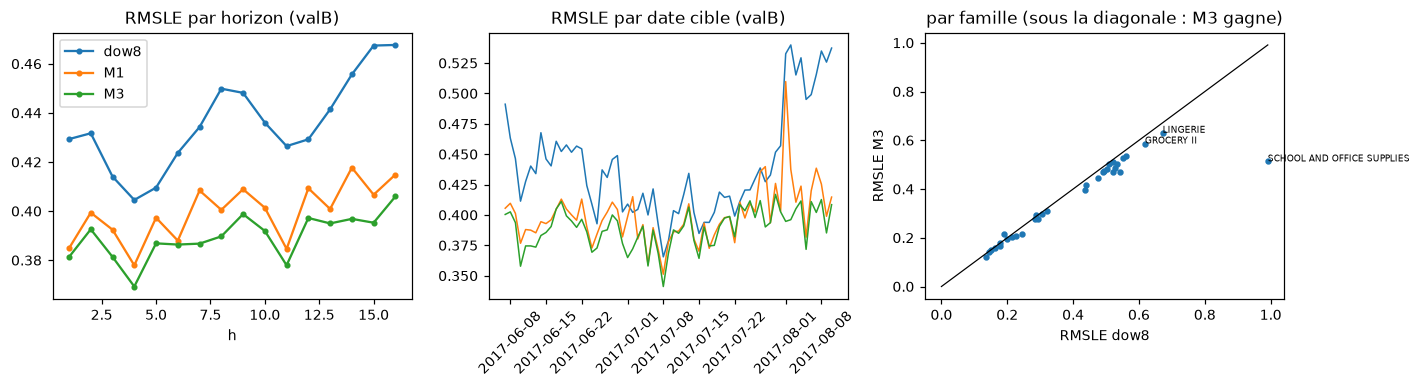

In [6]:
plot_benchmark(preds, v)

## 4. Choisir le lissage : GCV ou REML

`auto_fit` choisit les λ par GCV (défaut) ou REML ; `fit` garde les λ par défaut. Sur M2 avec splines (le réseau `n()` n'a pas de λ), un modèle par famille ; les λ sont communs aux 33 familles.

In [7]:
smooth = {}
for name, criterion in [('GCV', 'gcv'), ('REML', 'reml'), ('λ par défaut (fit)', None)]:
    m = ta.StaticTAM(formula=F_S, group_col='fam_id')
    with quiet():
        if criterion is None:
            m.fit(d['trainB'])
        else:
            m.auto_fit(d['trainB'], gamma=1.4, criterion=criterion)
        pred = m.predict(v)['Estimatedy']
    lam = m.summary().set_index('Feature')['Reg (log10)']
    smooth[name] = {'RMSLE valB': rmsle(v['y'], pred),
                    **{f'log10 λ {k}': float(lam[k]) for k in ('lvl7', 'dow8', 'promo_rel', 'dow', 'h')}}
pd.DataFrame(smooth).T

,RMSLE valB,log10 λ lvl7,log10 λ dow8,log10 λ promo_rel,log10 λ dow,log10 λ h
GCV,0.3916,-19.8000,-19.8000,-9.0000,-16.2000,-16.2000
REML,0.3914,-7.6800,-4.6100,-5.8300,-3.7500,3.8400
λ par défaut (fit),0.3916,-9.0000,-9.0000,-9.0000,-9.0000,-9.0000


## 5. Explicabilité avec les outils de TAM

Toutes les fonctions graphiques de TAM superposent les groupes : on se limite à GROCERY I (valB).

In [8]:
m3 = preds['M3']['model']
g = family_rows(d['trainB'], 'GROCERY I')
vg = family_rows(v, 'GROCERY I')
m3.summary()

,Feature,Type,Complexity (D),Structure / Params,Reg (log10)
0,offset,Offset,1,Global Bias,-9.0000
1,lvl7,Spline,13,"Knots=10, Diff(d=2)",-9.0000
2,lvl14,Linear,1,Slope (Ridge),-9.0000
3,lvl28,Linear,1,Slope (Ridge),-9.0000
4,lvl56,Linear,1,Slope (Ridge),-9.0000
5,dow8,Spline,13,"Knots=10, Diff(d=2)",-9.0000
6,dow,Categorical,7,"Cats=7, Topo=nominal, Unseen=edge",-9.0000
7,promo_rel,Spline,13,"Knots=10, Diff(d=2)",-9.0000
8,zero28,Linear,1,Slope (Ridge),-9.0000
9,nat_hol,Linear,1,Slope (Ridge),-9.0000


composantes : ['offset', 's_lvl7', 'lvl14', 'lvl28', 'lvl56', 'dow8', 'dow', 'promo_rel', 'zero28', 'nat_hol', 'nat_add', 'loc_hol', 'payday', 'h', 'newyear', 'dom1', 'dom2', 'te_lvl7_x_h', 'n_lvl7']


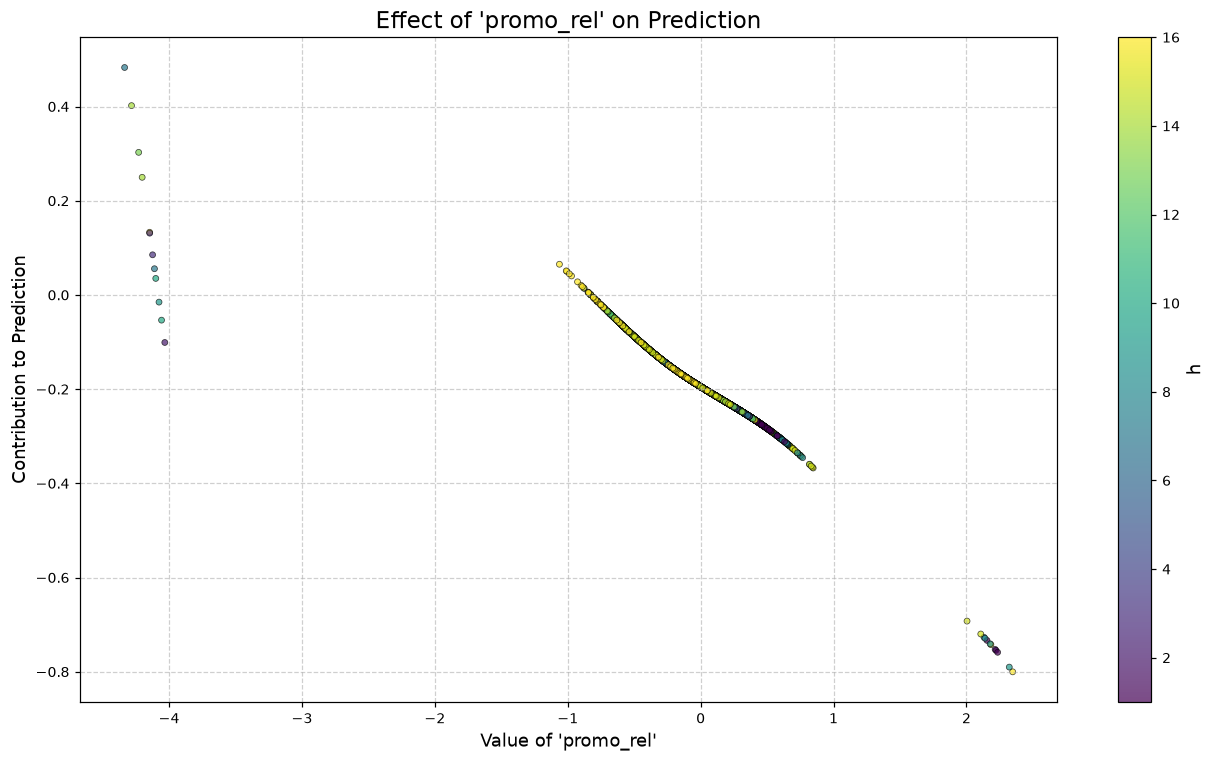

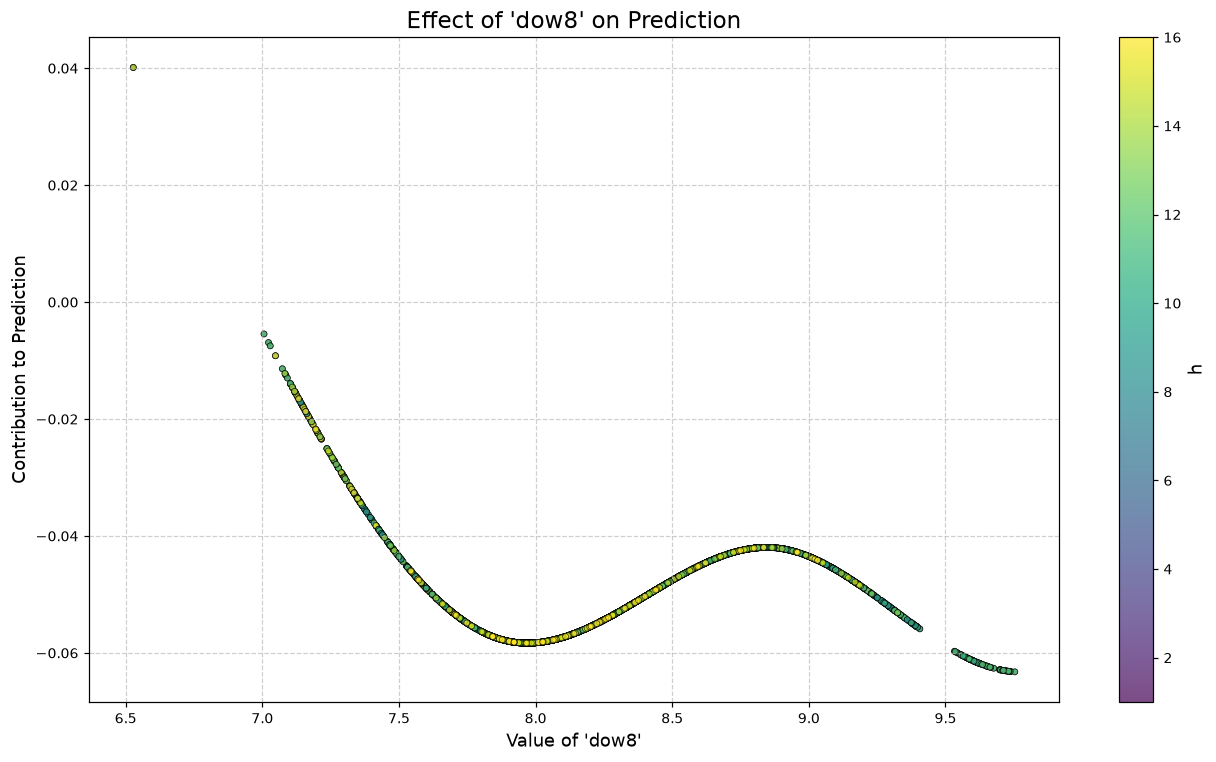

In [9]:
# Contribution de chaque effet contre sa variable (decompose_prediction : la somme des colonnes effect_* = la prévision)
with quiet():
    dec = m3.decompose_prediction(vg)
print('composantes :', [c[7:] for c in dec.columns if c.startswith('effect_')])
plot_effect_with_data_decomposed(dec, 'promo_rel', color_by='h')
plot_effect_with_data_decomposed(dec, 'dow8', color_by='h')

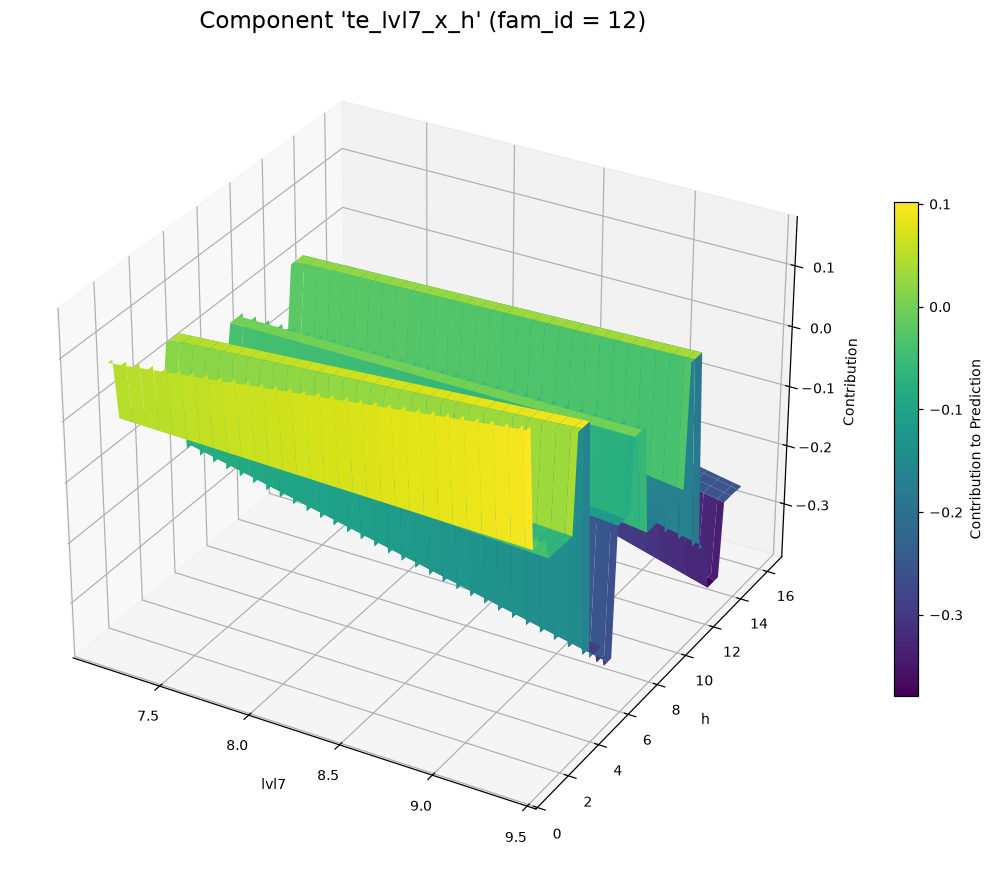

In [10]:
# L'interaction niveau x horizon : une courbe par horizon
fig = plot_component(m3, vg, 'te_lvl7_x_h', group=int(g['fam_id'].iloc[0]))
plt.show()

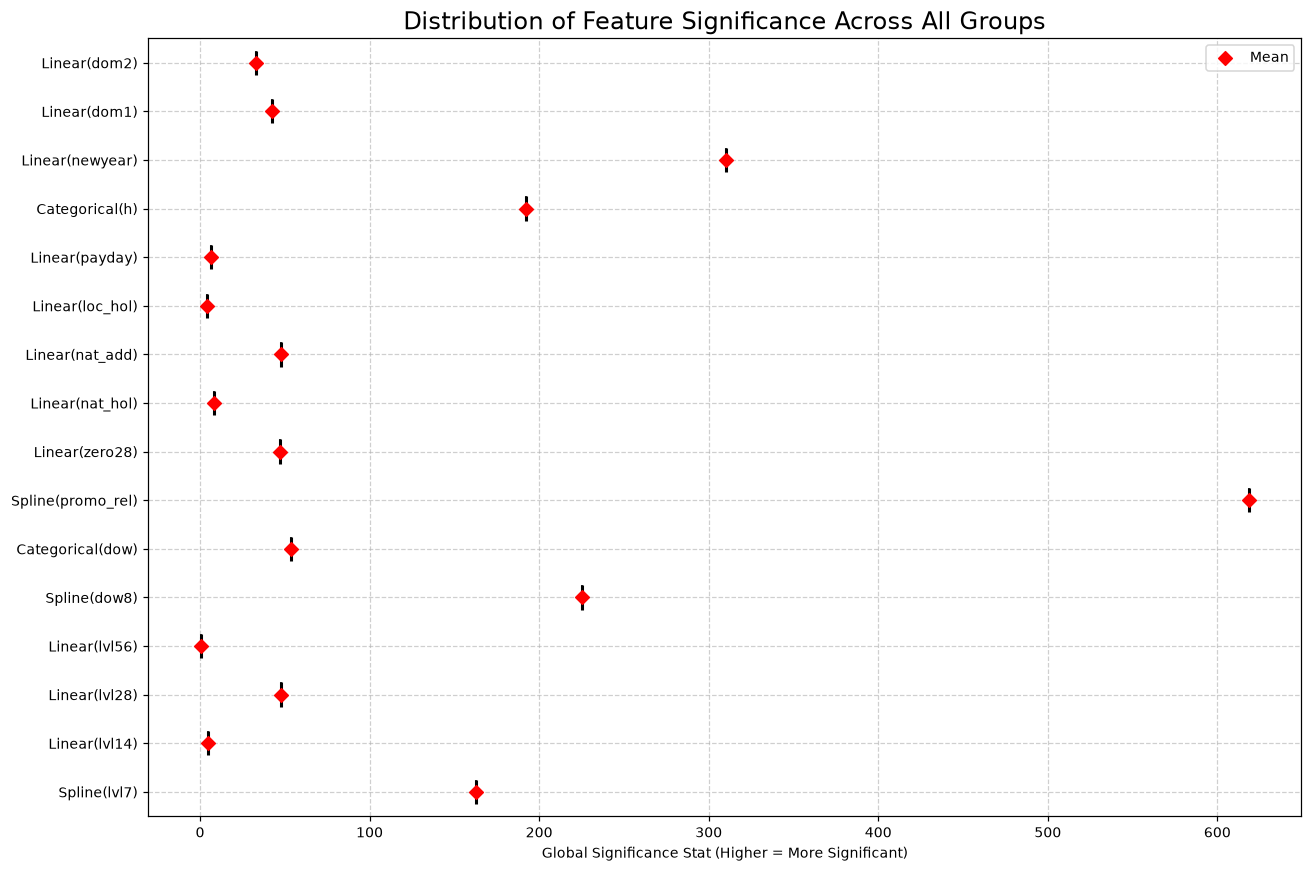

In [11]:
# Significativité globale par effet (|t| x nombre de coefficients) : un classement, pas un test ; elle dépend de λ.
# Sur un modèle GROCERY I seul (M2 avec splines, λ par GCV). run_diagnostics n'ajoute pas les colonnes factices
# de groupe et de date que TAM crée à l'ajustement : on les injecte avec _ensure_dummies.
m_g = ta.StaticTAM(formula=F_S, group_col='fam_id')
with quiet():
    m_g.auto_fit(g, gamma=1.4)
    t_stats = run_diagnostics(m_g, _ensure_dummies(g, m_g.group_col_, m_g.date_col_))

## 6. Résidus avec `tam.evaluation`

In [12]:
# Métriques et déviance expliquée (valB, échelle log1p)
pd.DataFrame({name: {**{k: x for k, x in calculate_regression_metrics(v['y'].values, p['B']).items() if k in ('MAE', 'RMSE', 'R2')},
                     'déviance expliquée': deviance_explained(v['y'].values, p['B'])}
              for name, p in preds.items()}).T

,RMSE,MAE,R2,déviance expliquée
dow8,0.4360,0.2824,0.9704,0.9704
M1,0.3997,0.2756,0.9751,0.9751
M3,0.3897,0.2644,0.9763,0.9763


In [13]:
# Biais, dispersion, forme et autocorrélation d'ordre 1 par classe de demande.
# Lignes triées par (série, origine, horizon) : l'autocorrélation d'ordre 1 relie h et h + 1 d'une même prévision.
vr = v.assign(pred=preds['M3']['B']).sort_values(['series', 'origin', 'h'])
vr['r'] = vr['y'] - vr['pred']
by_class = {cl: analyze_residuals(s['y'].values, s['pred'].values) for cl, s in vr.groupby('classe')}
by_class['toutes'] = analyze_residuals(vr['y'].values, vr['pred'].values)
vd = vr.sort_values('date')
print(f"dégradation dans le temps (RMSE de la 2e moitié de valB / 1re) : "
      f"{detect_temporal_degradation(vd['y'].values, vd['pred'].values):+.1f} %")
pd.DataFrame(by_class).T

dégradation dans le temps (RMSE de la 2e moitié de valB / 1re) : +2.8 %


,Mean Error (Bias),Std Error,Skewness,Kurtosis,Lag-1 AutoCorr
erratique,0.0078,0.5379,0.1084,2.7122,0.2240
grumeleuse,-0.0403,0.4959,0.1580,1.1871,0.1711
intermittente,-0.0160,0.3996,0.5029,1.1826,0.1038
jamais vendue,-0.0086,0.0489,15.7204,434.6195,0.2857
régulière,0.0010,0.3382,-0.3034,5.1388,0.1662
toutes,-0.0031,0.3897,0.0109,4.3548,0.1762


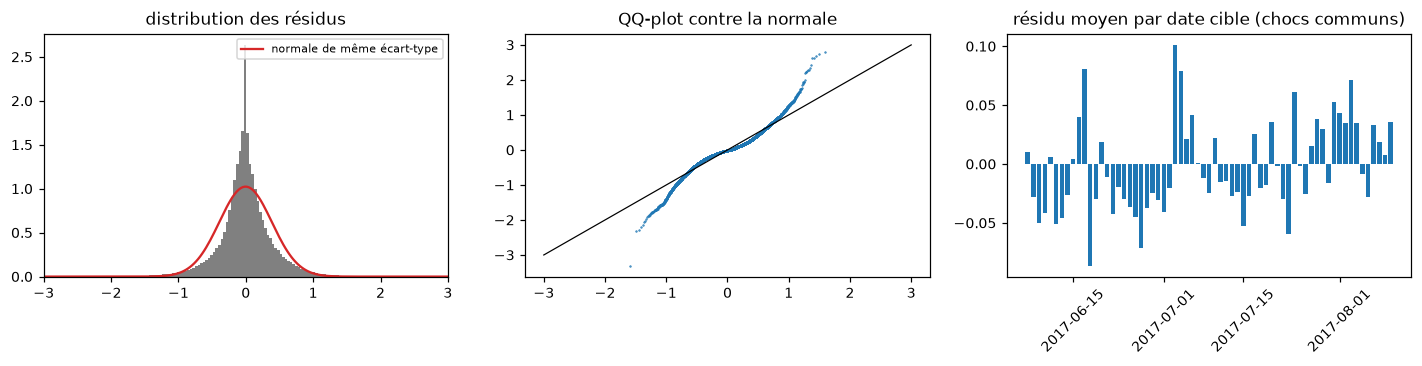

In [14]:
plot_residuals(vr)